
|------ ADIVINA EL NÚMERO ------|

1. Partida modo solitario 
2. Partida 2 jugadores 
3. Estadísticas 
4. Salir



Seleccione una opción del menú:  2



1. 1-1000 
2. 1-2000 
3. 1-3000



Seleccione el intervalo en el que estará el número a adivinar:  400


Debe ser menor o igual que 3.



Seleccione el intervalo en el que estará el número a adivinar:  3


... (33 outputs left out)


Seleccione una opción del menú:  3



=== ESTADÍSTICAS GENERALES ===
  Jugador         Modo Dificultad  Intentos Resultado
0   Jaime    Solitario    Difícil         5    Pierde
1   Jaime    Solitario      Medio         9      Gana
2  Silvia  2 Jugadores      Fácil        12      Gana
3   jaime  2 Jugadores      Medio         9      Gana
4     Ana    Solitario      Medio        11      Gana
5   Laura  2 Jugadores      Fácil         8      Gana



Si desea ver estadísticas por jugador, introduzca el número 1. Para volver al menú principal, introduzca cualquier otra tecla:  1
Introduzca el nombre del jugador:  laura


  Jugador         Modo Dificultad  Intentos Resultado
5   Laura  2 Jugadores      Fácil         8      Gana

Resumen:
Resultado
Gana    1
Name: count, dtype: int64


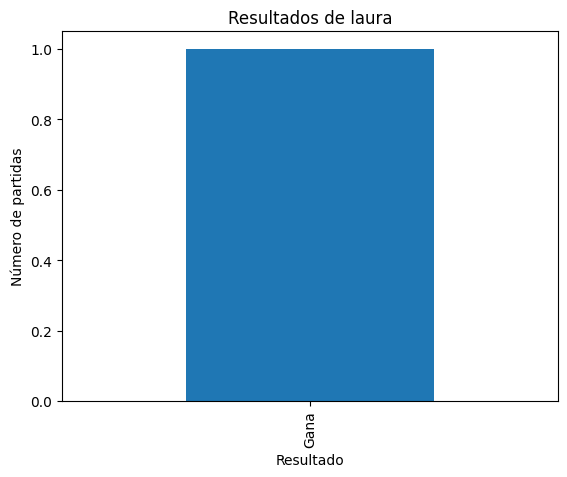


|------ ADIVINA EL NÚMERO ------|

1. Partida modo solitario 
2. Partida 2 jugadores 
3. Estadísticas 
4. Salir



Seleccione una opción del menú:  1



1. Fácil (20 intentos) 
2. Medio (12 intentos) 
3. Difícil (5 intentos)



Seleccione la dificultad:  3



1. 1-1000 
2. 1-2000 
3. 1-3000



Seleccione el intervalo en el que estará el número a adivinar:  2

Intento 1 de 5:  1000


... (11 outputs left out)


Seleccione una opción del menú:  3



=== ESTADÍSTICAS GENERALES ===
  Jugador         Modo Dificultad  Intentos Resultado
0   Jaime    Solitario    Difícil         5    Pierde
1   Jaime    Solitario      Medio         9      Gana
2  Silvia  2 Jugadores      Fácil        12      Gana
3   jaime  2 Jugadores      Medio         9      Gana
4     Ana    Solitario      Medio        11      Gana
5   Laura  2 Jugadores      Fácil         8      Gana
6   Laura    Solitario    Difícil         5    Pierde



Si desea ver estadísticas por jugador, introduzca el número 1. Para volver al menú principal, introduzca cualquier otra tecla:  1
Introduzca el nombre del jugador:  laura


  Jugador         Modo Dificultad  Intentos Resultado
5   Laura  2 Jugadores      Fácil         8      Gana
6   Laura    Solitario    Difícil         5    Pierde

Resumen:
Resultado
Gana      1
Pierde    1
Name: count, dtype: int64


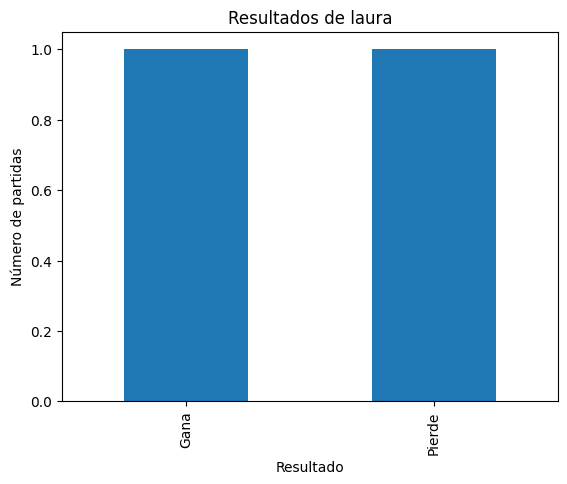


|------ ADIVINA EL NÚMERO ------|

1. Partida modo solitario 
2. Partida 2 jugadores 
3. Estadísticas 
4. Salir



Seleccione una opción del menú:  4



¡Hasta luego!


In [1]:
import random
import getpass
import pandas as pd
import openpyxl
import os
import matplotlib.pyplot as plt

ruta_excel = "C:\\Users\\jaime\\Estadísticas_AdivinaElNúmero.xlsx"
if not os.path.exists(ruta_excel):
    tabla = pd.DataFrame(columns=["Jugador", "Modo", "Dificultad", "Intentos", "Resultado"])
    tabla.to_excel(ruta_excel, index=False, sheet_name="Estadísticas")

documento_excel = openpyxl.load_workbook(ruta_excel)
hoja_excel = documento_excel["Estadísticas"]

def Elegir_numero(textito, minimo=None, maximo=None):
    while True:
        try:
            x = int(input(textito))
            if minimo is not None and x < minimo:
                print(f"Debe ser mayor o igual que {minimo}.")
                continue
            if maximo is not None and x > maximo:
                print(f"Debe ser menor o igual que {maximo}.")
                continue
            return x
        except ValueError:
            print("\nIntroduzca un número válido.")


def Elegir_dificultad():
    print("\n1. Fácil (20 intentos) \n2. Medio (12 intentos) \n3. Difícil (5 intentos)")
    opcion = Elegir_numero("\nSeleccione la dificultad: ", 1, 3)
    if opcion == 1:
        return 20, "Fácil"
    elif opcion == 2:
        return 12, "Medio"
    else:
        return 5, "Difícil"


def Elegir_intervalo():
    print("\n1. 1-1000 \n2. 1-2000 \n3. 1-3000")
    opcion = Elegir_numero("\nSeleccione el intervalo en el que estará el número a adivinar: ", 1, 3)
    if opcion == 1:
        return 1, 1000
    elif opcion == 2:
        return 1, 2000
    else:
        return 1, 3000


def Guardar_resultado(nombre, modo, dificultad, intentos, resultado):
    tabla = pd.read_excel(ruta_excel, sheet_name="Estadísticas")
    nuevo = pd.DataFrame([[nombre, modo, dificultad, intentos, resultado]],
                         columns=["Jugador", "Modo", "Dificultad", "Intentos", "Resultado"])
    tabla = pd.concat([tabla, nuevo], ignore_index=True)
    tabla.to_excel(ruta_excel, index=False, sheet_name="Estadísticas")


def Mostrar_estadisticas():
    tabla = pd.read_excel(ruta_excel, sheet_name="Estadísticas")
    if tabla.empty:
        print("\nNo hay estadísticas registradas todavía.")
        return
    print("\n=== ESTADÍSTICAS GENERALES ===")
    print(tabla)
    
    ver_detalle = input("\nSi desea ver estadísticas por jugador, introduzca el número 1. Para volver al menú principal, introduzca cualquier otra tecla: ")
    if ver_detalle == "1":
        jugador = input("Introduzca el nombre del jugador: ").strip()
        tabla_jugador = tabla[tabla["Jugador"].str.lower() == jugador.lower()]
        if tabla_jugador.empty:
            print(f"\nNo hay partidas registradas para '{jugador}'.")
        else:
            print(tabla_jugador)
            print("\nResumen:")
            print(tabla_jugador["Resultado"].value_counts())
            tabla_jugador["Resultado"].value_counts().plot(kind="bar", title=f"Resultados de {jugador}")
            plt.xlabel("Resultado")
            plt.ylabel("Número de partidas")
            plt.show()
            
def Jugar_partida(numero, intentos, minimo, maximo):
    for i in range(1, intentos + 1):
        x = Elegir_numero(f"\nIntento {i} de {intentos}: ", minimo, maximo)
        if x == numero:
            print("\n¡Ese es el número! ¡Enhorabuena!")
            return True, i
        elif i < intentos:
            if x < numero:
                print("\nEl número es mayor.")
            else:
                print("\nEl número es menor.")
    print(f"\nHa perdido. El número era {numero}.")
    return False, intentos


def Partida_modo_solitario():
    intentos, dificultad = Elegir_dificultad()
    minimo, maximo = Elegir_intervalo()
    numero = random.randint(minimo, maximo)
    resultado, intentos_usados = Jugar_partida(numero, intentos, minimo, maximo)

    nombre = input("\nIntroduzca su nombre: ").strip()
    Guardar_resultado(nombre, "Solitario", dificultad, intentos_usados, "Gana" if resultado else "Pierde")


def Partida_2_jugadores():
    minimo, maximo = Elegir_intervalo()
    print(f"\nJugador 1: escriba el número secreto entre {minimo} y {maximo}.")
    while True:
        try:
            numero = int(getpass.getpass("Número secreto (oculto): "))
            if minimo <= numero <= maximo:
                break
            else:
                print(f"Tiene que ser un número entre {minimo} y {maximo}.")
        except:
            print("Introduzca un número válido.")

    print("\nJugador 2, ¡es tu turno!")
    intentos, dificultad = Elegir_dificultad()
    resultado, intentos_usados = Jugar_partida(numero, intentos, minimo, maximo)

    nombre = input("\nIntroduzca el nombre del jugador 2: ").strip()
    Guardar_resultado(nombre, "2 Jugadores", dificultad, intentos_usados, "Gana" if resultado else "Pierde")

def Menu_principal():
    opcion = ""
    while opcion != "4":
        print("\n|------ ADIVINA EL NÚMERO ------|")
        print("\n1. Partida modo solitario \n2. Partida 2 jugadores \n3. Estadísticas \n4. Salir")
        opcion = input("\nSeleccione una opción del menú: ")

        while opcion not in ("1", "2", "3", "4"):
            opcion = input("\nSeleccione una opción válida (1-4): ")

        if opcion == "1":
            Partida_modo_solitario()
        elif opcion == "2":
            Partida_2_jugadores()
        elif opcion == "3":
            Mostrar_estadisticas()

    print("\n¡Hasta luego!")

if __name__ == "__main__":
    Menu_principal()